<a href="https://colab.research.google.com/github/Maybe1Harsh/indian-market-spiderweb/blob/main/indian_market_spiderweb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install yfinance

In [4]:
import matplotlib.pyplot as plt


In [5]:
import yfinance as yf, pandas as pd, numpy as np

In [6]:
tickers = [
 # banks
 "HDFCBANK","ICICIBANK","SBIN","AXISBANK","KOTAKBANK","INDUSINDBK","BANKBARODA",
 "PNB","CANBK","UNIONBANK","FEDERALBNK","IDFCFIRSTB","BANDHANBNK","AUBANK","YESBANK",
 # NBFCs
 "BAJFINANCE","BAJAJFINSV","CHOLAFIN","MUTHOOTFIN","MANAPPURAM","SHRIRAMFIN",
 "LICHSGFIN","PFC","RECLTD","M&MFIN","ABCAPITAL","SBICARD","POONAWALLA",
 # insurance
 "HDFCLIFE","SBILIFE","ICICIPRULI","ICICIGI","LICI",
 # fintech-adjacent / market infra
 "PAYTM","POLICYBZR","CDSL","BSE","ANGELONE","CAMS","HDFCAMC","MCX"
]

In [7]:
tickers = [t + ".NS" for t in tickers]

In [8]:
prices = yf.download(tickers, start="2017-01-01", auto_adjust=True)["Close"]

[*********************100%***********************]  41 of 41 completed


In [9]:
missing = prices.isna().mean().sort_values(ascending=False)
print(missing.round(2))

Ticker
LICI.NS          0.55
PAYTM.NS         0.50
POLICYBZR.NS     0.50
CAMS.NS          0.38
ANGELONE.NS      0.38
SBICARD.NS       0.32
HDFCAMC.NS       0.16
BANDHANBNK.NS    0.13
HDFCLIFE.NS      0.09
SBILIFE.NS       0.08
ICICIGI.NS       0.08
ABCAPITAL.NS     0.07
AUBANK.NS        0.05
CDSL.NS          0.05
BSE.NS           0.01
FEDERALBNK.NS    0.00
AXISBANK.NS      0.00
ICICIPRULI.NS    0.00
INDUSINDBK.NS    0.00
MUTHOOTFIN.NS    0.00
BAJAJFINSV.NS    0.00
BANKBARODA.NS    0.00
BAJFINANCE.NS    0.00
CANBK.NS         0.00
HDFCBANK.NS      0.00
LICHSGFIN.NS     0.00
KOTAKBANK.NS     0.00
ICICIBANK.NS     0.00
IDFCFIRSTB.NS    0.00
CHOLAFIN.NS      0.00
MANAPPURAM.NS    0.00
MCX.NS           0.00
M&MFIN.NS        0.00
PNB.NS           0.00
PFC.NS           0.00
RECLTD.NS        0.00
POONAWALLA.NS    0.00
SBIN.NS          0.00
SHRIRAMFIN.NS    0.00
UNIONBANK.NS     0.00
YESBANK.NS       0.00
dtype: float64


In [10]:
dropped = missing[missing > 0.20].index.tolist()
print("Dropped:", dropped)

Dropped: ['LICI.NS', 'PAYTM.NS', 'POLICYBZR.NS', 'CAMS.NS', 'ANGELONE.NS', 'SBICARD.NS']


In [11]:
clean = prices.drop(columns=dropped).ffill(limit=3)
returns = np.log(clean / clean.shift(1)).dropna(how="all")

In [12]:
print((returns.abs() > 0.25).sum().sort_values(ascending=False).head(10))

Ticker
YESBANK.NS       9
INDUSINDBK.NS    4
BANDHANBNK.NS    2
UNIONBANK.NS     1
PNB.NS           1
AXISBANK.NS      1
BAJAJFINSV.NS    1
CANBK.NS         1
CDSL.NS          1
BAJFINANCE.NS    1
dtype: int64


In [13]:
clean.to_csv("prices_40.csv")
returns.to_csv("returns_40.csv")
print(clean.shape)

(2426, 35)


In [14]:
returns.corr().to_csv("corr_matrix.csv")
print(returns.describe().T[["mean","std"]].round(4))

                 mean     std
Ticker                       
ABCAPITAL.NS   0.0002  0.0237
AUBANK.NS      0.0005  0.0237
AXISBANK.NS    0.0004  0.0204
BAJAJFINSV.NS  0.0007  0.0204
BAJFINANCE.NS  0.0010  0.0222
BANDHANBNK.NS -0.0005  0.0296
BANKBARODA.NS  0.0003  0.0251
BSE.NS         0.0015  0.0260
CANBK.NS       0.0004  0.0258
CDSL.NS        0.0007  0.0276
CHOLAFIN.NS    0.0009  0.0257
FEDERALBNK.NS  0.0007  0.0219
HDFCAMC.NS     0.0005  0.0202
HDFCBANK.NS    0.0004  0.0146
HDFCLIFE.NS    0.0002  0.0183
ICICIBANK.NS   0.0008  0.0182
ICICIGI.NS     0.0004  0.0183
ICICIPRULI.NS  0.0001  0.0203
IDFCFIRSTB.NS  0.0001  0.0231
INDUSINDBK.NS -0.0001  0.0265
KOTAKBANK.NS   0.0005  0.0165
LICHSGFIN.NS   0.0001  0.0221
M&MFIN.NS      0.0002  0.0263
MANAPPURAM.NS  0.0007  0.0262
MCX.NS         0.0011  0.0246
MUTHOOTFIN.NS  0.0009  0.0224
PFC.NS         0.0007  0.0236
PNB.NS         0.0001  0.0258
POONAWALLA.NS  0.0006  0.0289
RECLTD.NS      0.0008  0.0237
SBILIFE.NS     0.0004  0.0168
SBIN.NS   

In [15]:

import pandas as pd, numpy as np, networkx as nx, matplotlib.pyplot as plt

In [16]:
returns = pd.read_csv("returns_40.csv", index_col=0, parse_dates=True)
returns = returns.dropna(axis=1, thresh=int(0.8*len(returns))).dropna()
corr = returns.corr()




In [17]:
dist = np.sqrt(2 * (1 - corr))

In [18]:
G = nx.Graph()
cols = list(corr.columns)
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        G.add_edge(cols[i], cols[j], weight=dist.iloc[i, j])

In [19]:
mst = nx.minimum_spanning_tree(G)
print(mst.number_of_nodes(), mst.number_of_edges())

35 34


In [20]:
deg = nx.degree_centrality(mst)
btw = nx.betweenness_centrality(mst, weight="weight")
eig = nx.eigenvector_centrality_numpy(mst)


In [21]:
cent = pd.DataFrame({"degree": deg, "betweenness": btw, "eigenvector": eig})
cent["avg_rank"] = cent.rank(ascending=False).mean(axis=1)
cent = cent.sort_values("avg_rank")
print(cent.head(10).round(3))
cent.to_csv("centrality.csv")

               degree  betweenness  eigenvector  avg_rank
CANBK.NS        0.147        0.367        0.445     2.333
ICICIBANK.NS    0.118        0.561        0.354     2.833
SBIN.NS         0.088        0.665        0.419     3.500
FEDERALBNK.NS   0.118        0.469        0.314     3.833
BAJFINANCE.NS   0.088        0.472        0.233     5.500
CHOLAFIN.NS     0.118        0.223        0.159     7.500
PNB.NS          0.088        0.116        0.234     8.000
ABCAPITAL.NS    0.118        0.271        0.110     8.833
IDFCFIRSTB.NS   0.059        0.299        0.159    10.000
PFC.NS          0.059        0.059        0.195    12.333


In [22]:
sector = {}
for t in cols:
    n = t.replace(".NS", "")
    if n in ["HDFCLIFE","SBILIFE","ICICIPRULI","ICICIGI","LICI"]: sector[t] = "insurance"
    elif n in ["PAYTM","POLICYBZR","CDSL","BSE","ANGELONE","CAMS","HDFCAMC","MCX"]: sector[t] = "fintech/infra"
    elif n in ["BAJFINANCE","BAJAJFINSV","CHOLAFIN","MUTHOOTFIN","MANAPPURAM","SHRIRAMFIN",
               "LICHSGFIN","PFC","RECLTD","M&MFIN","ABCAPITAL","SBICARD","POONAWALLA"]: sector[t] = "NBFC"
    else: sector[t] = "bank"

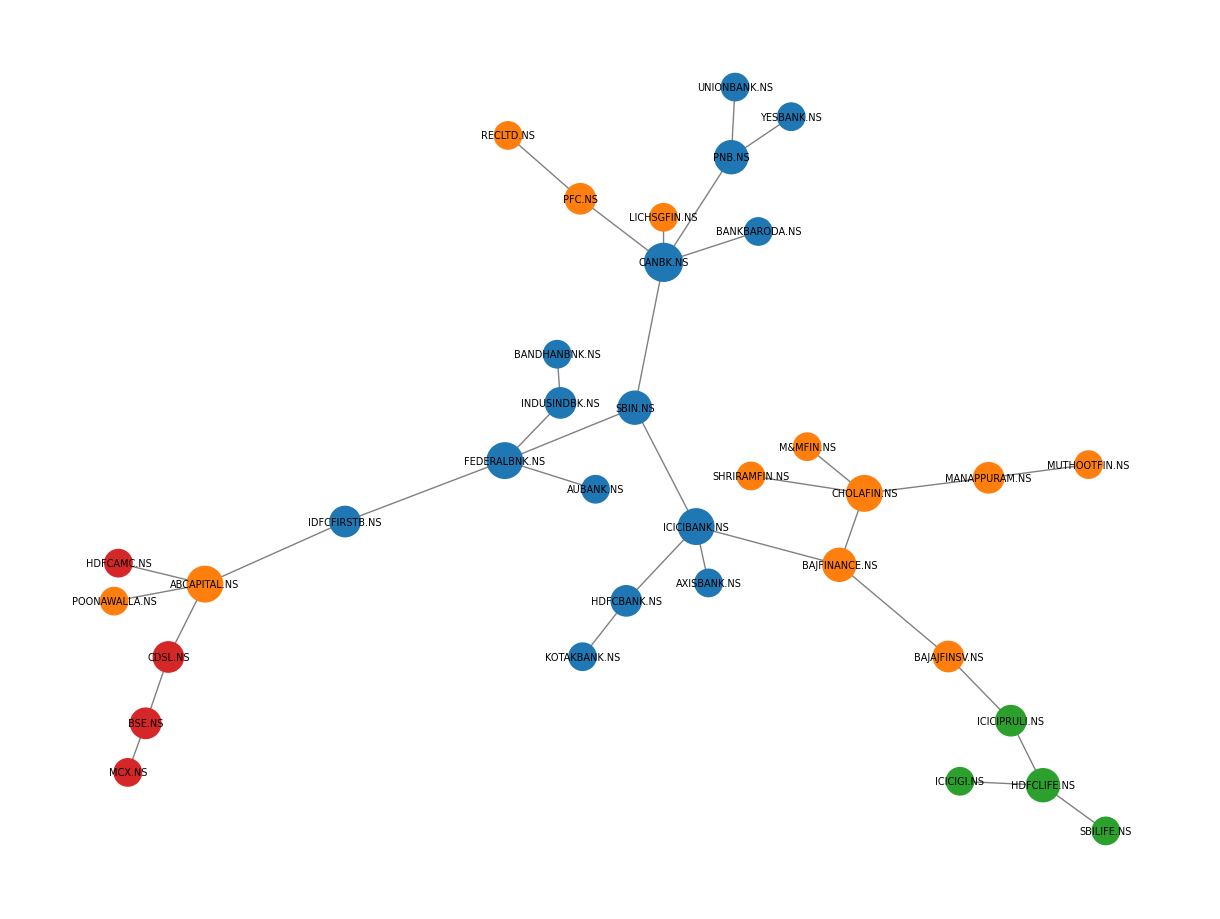

In [23]:
colors = {"bank":"tab:blue","NBFC":"tab:orange","insurance":"tab:green","fintech/infra":"tab:red"}
pos = nx.spring_layout(mst, seed=42)
plt.figure(figsize=(12, 9))
nx.draw(mst, pos, with_labels=True, font_size=7,
        node_color=[colors[sector[n]] for n in mst.nodes()],
        node_size=[300 + 3000*deg[n] for n in mst.nodes()], edge_color="gray")
plt.savefig("mst_network.png", dpi=150, bbox_inches="tight")
plt.show()

In [24]:
T = nx.Graph()
T.add_nodes_from(cols)
for i in range(len(cols)):
    for j in range(i+1, len(cols)):
        if corr.iloc[i, j] > 0.5:
            T.add_edge(cols[i], cols[j])

print("density:", round(nx.density(T), 3))
comms = nx.algorithms.community.greedy_modularity_communities(T)
for k, c in enumerate(comms):
    print(k, sorted(c))

density: 0.155
0 ['ABCAPITAL.NS', 'BANKBARODA.NS', 'CANBK.NS', 'IDFCFIRSTB.NS', 'LICHSGFIN.NS', 'PFC.NS', 'PNB.NS', 'RECLTD.NS', 'SBIN.NS', 'UNIONBANK.NS']
1 ['AXISBANK.NS', 'BAJAJFINSV.NS', 'BAJFINANCE.NS', 'CHOLAFIN.NS', 'HDFCBANK.NS', 'ICICIBANK.NS', 'KOTAKBANK.NS', 'M&MFIN.NS', 'SHRIRAMFIN.NS']
2 ['BANDHANBNK.NS', 'FEDERALBNK.NS', 'INDUSINDBK.NS']
3 ['HDFCLIFE.NS', 'ICICIPRULI.NS', 'SBILIFE.NS']
4 ['BSE.NS', 'CDSL.NS']
5 ['MANAPPURAM.NS', 'MUTHOOTFIN.NS']
6 ['AUBANK.NS']
7 ['HDFCAMC.NS']
8 ['ICICIGI.NS']
9 ['MCX.NS']
10 ['POONAWALLA.NS']
11 ['YESBANK.NS']


In [25]:
def avg_corr(start, end):
    c = returns.loc[start:end].corr().values
    return c[np.triu_indices_from(c, k=1)].mean()

periods = {"calm 2019": ("2019-01-01","2019-06-30"),
           "IL&FS Sep-Dec 2018": ("2018-09-01","2018-12-31"),
           "COVID Feb-Apr 2020": ("2020-02-15","2020-04-30"),
           "calm 2021": ("2021-06-01","2021-12-31")}
for name, (s, e) in periods.items():
    print(name, round(avg_corr(s, e), 3))

calm 2019 0.281
IL&FS Sep-Dec 2018 0.333
COVID Feb-Apr 2020 0.581
calm 2021 0.296
